# Rolling dynamic panel — 90-day windows

Replica of the 60-day workflow with a longer training block. The learner is still **dynamic panel FE OLS** (ZIP fixed effects + lagged/local predictors), not LightGBM.

| Piece | Length |
|---|---|
| Train | 90 days |
| Test | 39 days |
| Step to next window | 90 days |

Each window fits three models: targets at t+1, t+2, and t+3.

**How to read this notebook:** run top to bottom. Sections 1–6 show the method on window 0. Section 7 rolls all windows. Section 8 summarizes metrics. Section 9 plots actual vs predicted (test days only) and error over time.

**How to read the scores:** persistence means “future cases = today’s cases.” MAE is average absolute miss in cases. Skill = `1 - model_MAE / persistence_MAE` (positive means we beat the naive guess).


## 1. Paths and imports

The next cell loads helpers from `panel_window.py` and points at the supervised horizon files plus this folder’s `outputs/` directory.

In [1]:
from pathlib import Path
import sys

import pandas as pd

HERE = Path.cwd()
if not (HERE / "panel_window.py").is_file():
    HERE = HERE / "Weikun" / "rolling_dynamic_panel" / "window_90days"
assert (HERE / "panel_window.py").is_file(), "Open this notebook from window_90days or the repo root."

sys.path.insert(0, str(HERE))
from panel_window import (
    BLOCK_DAYS,
    TEST_DAYS,
    TRAIN_DAYS,
    load_horizon,
    ordered_dates,
    resolve_supervised_dir,
    run_window,
    top_non_fe_coefficients,
    window_bounds,
)

SUPERVISED = resolve_supervised_dir(HERE)
OUTPUT = HERE / "outputs"
OUTPUT.mkdir(parents=True, exist_ok=True)

print("Supervised dir:", SUPERVISED)
print("Output dir:", OUTPUT.resolve())
print(f"Train={TRAIN_DAYS} days | Test={TEST_DAYS} days | Block={BLOCK_DAYS} days")


Supervised dir: /Users/dhruvesh/Desktop/Fall 2026/Analytics/Jupyter/Weikun/supervised_horizon_outputs
Output dir: /Users/dhruvesh/Desktop/Fall 2026/Analytics/Jupyter/Weikun/rolling_dynamic_panel/window_90days/outputs
Train=90 days | Test=39 days | Block=129 days


## 2. Load the three horizon panels

Same predictors in each file; only `target_cases` changes (next day, two days ahead, three days ahead). Dates are shared from horizon 1 for the rolling calendar.

In [2]:
horizons = {h: load_horizon(SUPERVISED, h) for h in (1, 2, 3)}
dates = ordered_dates(horizons[1])

for h, frame in horizons.items():
    print(
        f"horizon {h}: {len(frame):,} rows | "
        f"{frame.zip.nunique()} ZIPs | "
        f"{frame.date.min().date()} to {frame.date.max().date()}"
    )

print("Calendar days available:", len(dates))
print("Max complete 90+39 windows:", 1 + (len(dates) - BLOCK_DAYS) // TRAIN_DAYS)

horizon 1: 629,527 rows | 456 ZIPs | 2020-02-15 to 2023-12-30
horizon 2: 629,071 rows | 456 ZIPs | 2020-02-15 to 2023-12-29
horizon 3: 628,615 rows | 456 ZIPs | 2020-02-15 to 2023-12-28
Calendar days available: 1415
Max complete 90+39 windows: 15


## 3. Define window 0

First 90 calendar days for training, next 39 for testing. Training labels are also required to fall on or before the last train day so the answer does not sit inside the test block.

In [3]:
WINDOW_ID = 0
bounds = window_bounds(dates, WINDOW_ID)

pd.DataFrame([
    {
        "window_id": WINDOW_ID,
        "train_start": bounds["train_start"].date(),
        "train_end": bounds["train_end"].date(),
        "test_start": bounds["test_start"].date(),
        "test_end": bounds["test_end"].date(),
        "train_days": TRAIN_DAYS,
        "test_days": TEST_DAYS,
    }
])

,window_id,train_start,train_end,test_start,test_end,train_days,test_days
0,0,2020-02-15,2020-05-14,2020-05-15,2020-06-22,90,39


## 4. Fit three FE OLS models on window 0

One model per horizon. Coefficients are estimated on the train block only, then applied to the test block with the realized history available on each test day. Predictions are clipped at zero. Persistence uses `cases_today` as the naive guess for every horizon.

In [4]:
result = run_window(horizons, dates, WINDOW_ID)
metrics = result["metrics"]
coefficients = result["coefficients"]
predictions = result["predictions"]

metrics.to_csv(OUTPUT / "window_metrics.csv", index=False)
coefficients.to_csv(OUTPUT / "feature_coefficients.csv", index=False)
predictions.to_csv(OUTPUT / "predictions_test.csv.gz", index=False, compression="gzip")

print("Saved:", OUTPUT / "window_metrics.csv")
print("Saved:", OUTPUT / "feature_coefficients.csv")
print("Saved:", OUTPUT / "predictions_test.csv.gz")

Saved: /Users/dhruvesh/Desktop/Fall 2026/Analytics/Jupyter/Weikun/rolling_dynamic_panel/window_90days/outputs/window_metrics.csv
Saved: /Users/dhruvesh/Desktop/Fall 2026/Analytics/Jupyter/Weikun/rolling_dynamic_panel/window_90days/outputs/feature_coefficients.csv
Saved: /Users/dhruvesh/Desktop/Fall 2026/Analytics/Jupyter/Weikun/rolling_dynamic_panel/window_90days/outputs/predictions_test.csv.gz


## 5. Result tables for window 0

Read in order:

- **Table A:** which dates were train vs test, and sample sizes
- **Table B:** model vs persistence (MAE, RMSE, mean error, skill)
- **Tables C–D:** largest |coefficients| among non-ZIP terms for horizons 1 and 3

Skill > 0 means the panel model beat “future = today” on MAE for that horizon.

In [5]:
print("Table A — window identity and sample sizes")
display(metrics[[
    "window_id", "train_start", "train_end", "test_start", "test_end",
    "horizon_days", "train_rows", "test_rows", "n_zips_train", "n_zips_test",
    "n_design_columns", "rank_deficient",
]].round(3))

print("Table B — scorecard vs persistence")
scorecard = metrics[[
    "horizon_days",
    "model_MAE", "model_RMSE", "model_mean_error",
    "persistence_MAE", "persistence_RMSE",
    "skill_vs_persistence",
]].copy()
display(scorecard.round(3))

print("Table C — top |coefficients| excluding ZIP fixed effects (horizon 1)")
display(top_non_fe_coefficients(coefficients, horizon=1, n=10))

print("Table D — top |coefficients| excluding ZIP fixed effects (horizon 3)")
display(top_non_fe_coefficients(coefficients, horizon=3, n=10))

Table A — window identity and sample sizes


,window_id,train_start,train_end,test_start,test_end,horizon_days,train_rows,test_rows,n_zips_train,n_zips_test,n_design_columns,rank_deficient
0,0,2020-02-15,2020-05-14,2020-05-15,2020-06-22,1,28201,17006,436,437,465,True
1,0,2020-02-15,2020-05-14,2020-05-15,2020-06-22,2,27765,17006,436,437,465,True
2,0,2020-02-15,2020-05-14,2020-05-15,2020-06-22,3,27329,17006,436,437,465,True


Table B — scorecard vs persistence


,horizon_days,model_MAE,model_RMSE,model_mean_error,persistence_MAE,persistence_RMSE,skill_vs_persistence
0,1,0.452,0.812,0.213,0.316,0.826,-0.429
1,2,0.405,0.841,0.130,0.325,0.840,-0.248
2,3,0.432,0.924,0.165,0.323,0.835,-0.338


Table C — top |coefficients| excluding ZIP fixed effects (horizon 1)


,term,coefficient,horizon_days,window_id,is_fixed_effect,abs_coefficient
0,month_3,0.512250,1,0,False,0.512250
1,day_of_week_7,0.459729,1,0,False,0.459729
2,case_std_14d,0.449680,1,0,False,0.449680
3,intercept,-0.405605,1,0,False,0.405605
4,day_of_week_6,-0.347874,1,0,False,0.347874
5,case_std_7d,-0.337247,1,0,False,0.337247
6,day_of_week_4,0.296171,1,0,False,0.296171
7,day_of_week_5,-0.283784,1,0,False,0.283784
8,cases_lag_1,0.200069,1,0,False,0.200069
9,day_of_week_2,0.186439,1,0,False,0.186439


Table D — top |coefficients| excluding ZIP fixed effects (horizon 3)


,term,coefficient,horizon_days,window_id,is_fixed_effect,abs_coefficient
0,month_3,1.071958,3,0,False,1.071958
1,intercept,-0.865913,3,0,False,0.865913
2,month_4,0.779344,3,0,False,0.779344
3,month_5,0.550190,3,0,False,0.550190
4,day_of_week_5,0.525359,3,0,False,0.525359
5,case_std_14d,0.505025,3,0,False,0.505025
6,day_of_week_2,0.384185,3,0,False,0.384185
7,day_of_week_7,0.343265,3,0,False,0.343265
8,case_std_7d,-0.298698,3,0,False,0.298698
9,day_of_week_3,-0.278091,3,0,False,0.278091


## 6. Quick prediction preview

A few test rows for one ZIP so you can see actual, panel prediction, and persistence side by side. Full-roll plots come in a later phase.

In [6]:
example_zip = "07302" if predictions.zip.eq("07302").any() else predictions.zip.iloc[0]
preview = (
    predictions.loc[predictions.zip.eq(example_zip) & predictions.horizon_days.eq(1)]
    .sort_values("date")
    .loc[:, ["window_id", "zip", "date", "target_date", "actual_cases",
             "panel_prediction", "persistence_prediction"]]
    .head(10)
)
print(f"Horizon 1 test preview for ZIP {example_zip}")
preview

Horizon 1 test preview for ZIP 07302


,window_id,zip,date,target_date,actual_cases,panel_prediction,persistence_prediction
87,0,07302,2020-05-15,2020-05-16,0,0.951046,1
523,0,07302,2020-05-16,2020-05-17,0,0.807821,0
959,0,07302,2020-05-17,2020-05-18,0,1.549723,0
1395,0,07302,2020-05-18,2020-05-19,0,1.171942,0
1831,0,07302,2020-05-19,2020-05-20,0,0.888092,0
2267,0,07302,2020-05-20,2020-05-21,0,0.922729,0
2703,0,07302,2020-05-21,2020-05-22,1,1.272124,0
3139,0,07302,2020-05-22,2020-05-23,0,0.693184,1
3575,0,07302,2020-05-23,2020-05-24,0,0.575567,0
4011,0,07302,2020-05-24,2020-05-25,1,1.462600,0


## 7. Roll every complete 90+39 window

Same fit/score logic as window 0, stepped forward by 90 days until a full train+test block no longer fits. Overwrites `outputs/` with the full-run metrics, coefficients, and test predictions.

In [7]:
n_windows = 1 + (len(dates) - BLOCK_DAYS) // TRAIN_DAYS
print(f"Complete windows to run: {n_windows}")

metric_parts = []
coef_parts = []
pred_parts = []

for window_id in range(n_windows):
    bounds = window_bounds(dates, window_id)
    result = run_window(horizons, dates, window_id)
    metric_parts.append(result["metrics"])
    coef_parts.append(result["coefficients"])
    pred_parts.append(result["predictions"])
    row = result["metrics"].loc[result["metrics"].horizon_days.eq(1)].iloc[0]
    print(
        f"window {window_id:02d} | "
        f"train {bounds['train_start'].date()} to {bounds['train_end'].date()} | "
        f"test {bounds['test_start'].date()} to {bounds['test_end'].date()} | "
        f"MAE(h1)={row.model_MAE:.3f} skill={row.skill_vs_persistence:.3f}"
    )

metrics = pd.concat(metric_parts, ignore_index=True)
coefficients = pd.concat(coef_parts, ignore_index=True)
predictions = pd.concat(pred_parts, ignore_index=True)

metrics.to_csv(OUTPUT / "window_metrics.csv", index=False)
coefficients.to_csv(OUTPUT / "feature_coefficients.csv", index=False)
predictions.to_csv(OUTPUT / "predictions_test.csv.gz", index=False, compression="gzip")

print("Saved full-run outputs to", OUTPUT.resolve())
print(metrics.groupby("horizon_days")[["model_MAE", "persistence_MAE", "skill_vs_persistence"]].mean().round(3))

Complete windows to run: 15
window 00 | train 2020-02-15 to 2020-05-14 | test 2020-05-15 to 2020-06-22 | MAE(h1)=0.452 skill=-0.429
window 01 | train 2020-05-15 to 2020-08-12 | test 2020-08-13 to 2020-09-20 | MAE(h1)=0.337 skill=0.082
window 02 | train 2020-08-13 to 2020-11-10 | test 2020-11-11 to 2020-12-19 | MAE(h1)=1.559 skill=0.081
window 03 | train 2020-11-11 to 2021-02-08 | test 2021-02-09 to 2021-03-19 | MAE(h1)=1.203 skill=0.216
window 04 | train 2021-02-09 to 2021-05-09 | test 2021-05-10 to 2021-06-17 | MAE(h1)=0.485 skill=-0.638
window 05 | train 2021-05-10 to 2021-08-07 | test 2021-08-08 to 2021-09-15 | MAE(h1)=0.941 skill=0.165
window 06 | train 2021-08-08 to 2021-11-05 | test 2021-11-06 to 2021-12-14 | MAE(h1)=1.317 skill=0.123
window 07 | train 2021-11-06 to 2022-02-03 | test 2022-02-04 to 2022-03-14 | MAE(h1)=0.655 skill=-0.075
window 08 | train 2022-02-04 to 2022-05-04 | test 2022-05-05 to 2022-06-12 | MAE(h1)=1.031 skill=0.182
window 09 | train 2022-05-05 to 2022-08-02

## 8. Aggregate result tables

One window is only one quiz. These tables summarize all complete quizzes.

- **Table 1:** average / median error by horizon, and how often we beat persistence
- **Table 2:** each window’s MAE and skill over calendar time
- **Table 3:** which non-ZIP features most often land in the top 5 |coefficients|
- **Table 4:** one-line summary

A negative *mean* skill with a near-zero *median* skill usually means a few quiet periods inflate the average ratio; check Table 2 before concluding the model always loses.

In [8]:
# Reload full-run metrics if the kernel was restarted after the roll.
metrics = pd.read_csv(OUTPUT / "window_metrics.csv", parse_dates=[
    "train_start", "train_end", "test_start", "test_end"
])
coefficients = pd.read_csv(OUTPUT / "feature_coefficients.csv")

by_horizon = metrics.groupby("horizon_days").agg(
    n_windows=("window_id", "nunique"),
    mean_model_MAE=("model_MAE", "mean"),
    median_model_MAE=("model_MAE", "median"),
    mean_persistence_MAE=("persistence_MAE", "mean"),
    median_persistence_MAE=("persistence_MAE", "median"),
    mean_model_RMSE=("model_RMSE", "mean"),
    mean_persistence_RMSE=("persistence_RMSE", "mean"),
    mean_skill=("skill_vs_persistence", "mean"),
    median_skill=("skill_vs_persistence", "median"),
    share_windows_beat_persistence=("skill_vs_persistence", lambda s: float((s > 0).mean())),
).reset_index()

by_window = metrics.pivot_table(
    index=["window_id", "train_start", "train_end", "test_start", "test_end"],
    columns="horizon_days",
    values=["model_MAE", "persistence_MAE", "skill_vs_persistence"],
).reset_index()
by_window.columns = [
    "_".join(str(c) for c in col).strip("_") if isinstance(col, tuple) else col
    for col in by_window.columns
]

nonfe = coefficients.loc[~coefficients.is_fixed_effect & ~coefficients.term.eq("intercept")].copy()
nonfe["abs_coefficient"] = nonfe.coefficient.abs()
top_rows = []
for (window_id, horizon), group in nonfe.groupby(["window_id", "horizon_days"]):
    top = group.nlargest(5, "abs_coefficient")
    for rank, row in enumerate(top.itertuples(index=False), start=1):
        top_rows.append({
            "window_id": window_id,
            "horizon_days": horizon,
            "rank": rank,
            "term": row.term,
            "abs_coefficient": row.abs_coefficient,
        })
top_hits = pd.DataFrame(top_rows)
stability = (
    top_hits.groupby(["horizon_days", "term"]).size()
    .reset_index(name="times_in_top5")
    .sort_values(["horizon_days", "times_in_top5"], ascending=[True, False])
)
stability_top = pd.concat(
    [stability.loc[stability.horizon_days.eq(h)].head(10) for h in (1, 2, 3)],
    ignore_index=True,
)

h1 = metrics.loc[metrics.horizon_days.eq(1)]
summary = pd.DataFrame([{
    "n_windows": int(metrics.window_id.nunique()),
    "n_metric_rows": len(metrics),
    "horizons": "1,2,3",
    "share_windows_h1_beat_persistence": float((h1.skill_vs_persistence > 0).mean()),
    "mean_model_MAE_h1": float(h1.model_MAE.mean()),
    "mean_persistence_MAE_h1": float(h1.persistence_MAE.mean()),
}])

by_horizon.to_csv(OUTPUT / "aggregate_metrics_by_horizon.csv", index=False)
by_window.to_csv(OUTPUT / "aggregate_metrics_by_window.csv", index=False)
stability_top.to_csv(OUTPUT / "feature_stability_top5.csv", index=False)
summary.to_csv(OUTPUT / "aggregate_metrics.csv", index=False)

print("Table 1 — overall by horizon")
display(by_horizon.round(3))

print("Table 2 — each window over calendar time (MAE and skill)")
display(by_window.round(3))

print("Table 3 — features most often in the top 5 |coefficient| (excluding ZIP FE and intercept)")
display(stability_top)

print("Table 4 — one-line summary")
display(summary.round(3))

Table 1 — overall by horizon


,horizon_days,n_windows,mean_model_MAE,median_model_MAE,mean_persistence_MAE,median_persistence_MAE,mean_model_RMSE,mean_persistence_RMSE,mean_skill,median_skill,share_windows_beat_persistence
0,1,15,0.680,0.592,0.723,0.609,1.079,1.267,-0.535,0.074,0.533
1,2,15,0.716,0.596,0.734,0.619,1.138,1.291,-0.516,-0.024,0.467
2,3,15,0.752,0.607,0.746,0.619,1.203,1.316,-0.440,-0.038,0.467


Table 2 — each window over calendar time (MAE and skill)


/var/folders/9g/dc1_4w692z950j8_8mfyy4rc0000gn/T/ipykernel_8751/2148840617.py:73: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(by_window.round(3))


,window_id,train_start,train_end,test_start,test_end,model_MAE_1,model_MAE_2,model_MAE_3,persistence_MAE_1,persistence_MAE_2,persistence_MAE_3,skill_vs_persistence_1,skill_vs_persistence_2,skill_vs_persistence_3
0,0,2020-02-15,2020-05-14,2020-05-15,2020-06-22,0.452,0.405,0.432,0.316,0.325,0.323,-0.429,-0.248,-0.338
1,1,2020-05-15,2020-08-12,2020-08-13,2020-09-20,0.337,0.348,0.352,0.367,0.380,0.384,0.082,0.084,0.082
2,2,2020-08-13,2020-11-10,2020-11-11,2020-12-19,1.559,1.795,2.021,1.697,1.715,1.744,0.081,-0.047,-0.159
3,3,2020-11-11,2021-02-08,2021-02-09,2021-03-19,1.203,1.213,1.250,1.534,1.555,1.599,0.216,0.219,0.219
4,4,2021-02-09,2021-05-09,2021-05-10,2021-06-17,0.485,0.545,0.607,0.296,0.302,0.292,-0.638,-0.803,-1.081
5,5,2021-05-10,2021-08-07,2021-08-08,2021-09-15,0.941,0.961,0.976,1.126,1.134,1.145,0.165,0.152,0.148
6,6,2021-08-08,2021-11-05,2021-11-06,2021-12-14,1.317,1.397,1.480,1.502,1.536,1.613,0.123,0.090,0.082
7,7,2021-11-06,2022-02-03,2022-02-04,2022-03-14,0.655,0.741,0.814,0.609,0.619,0.619,-0.075,-0.198,-0.316
8,8,2022-02-04,2022-05-04,2022-05-05,2022-06-12,1.031,1.060,1.077,1.261,1.286,1.299,0.182,0.176,0.171
9,9,2022-05-05,2022-08-02,2022-08-03,2022-09-10,0.722,0.766,0.796,0.779,0.795,0.812,0.074,0.036,0.020


Table 3 — features most often in the top 5 |coefficient| (excluding ZIP FE and intercept)


,horizon_days,term,times_in_top5
0,1,day_of_week_5,10
1,1,day_of_week_7,9
2,1,case_std_14d,8
3,1,day_of_week_3,7
4,1,case_std_7d,5
5,1,day_of_week_4,5
6,1,day_of_week_6,5
7,1,cases_lag_1,3
8,1,day_of_week_2,3
9,1,case_acceleration,2


Table 4 — one-line summary


,n_windows,n_metric_rows,horizons,share_windows_h1_beat_persistence,mean_model_MAE_h1,mean_persistence_MAE_h1
0,15,45,"1,2,3",0.533,0.68,0.723


## 9. Visualizations

Predictions exist only on each window’s **test** days, so the blue predicted line will show gaps. That is intentional: train spans are study time, not scored forecasts.

Plot A: MAE by window over calendar time (three horizons).
Plot B: actual cases (continuous from the supervised panel) vs panel predictions on test days for three example ZIPs, horizon t+1.

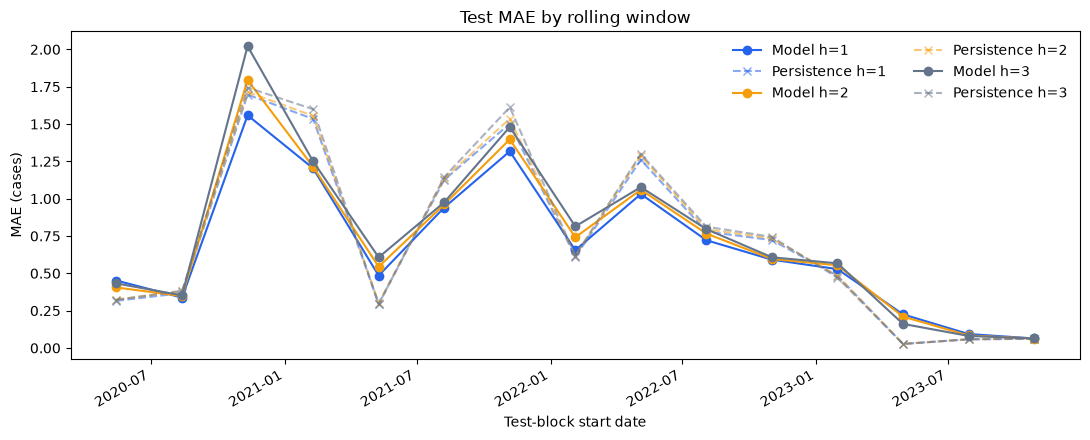

In [9]:
import matplotlib.pyplot as plt

FIGDIR = OUTPUT / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)

metrics = pd.read_csv(
    OUTPUT / "window_metrics.csv",
    parse_dates=["train_start", "train_end", "test_start", "test_end"],
)
predictions = pd.read_csv(
    OUTPUT / "predictions_test.csv.gz",
    dtype={"zip": "string"},
    parse_dates=["date", "target_date"],
)

# Plot A — error across rolling quizzes
fig, ax = plt.subplots(figsize=(11, 4.5))
for horizon, color in [(1, "#2563EB"), (2, "#F59E0B"), (3, "#64748B")]:
    part = metrics.loc[metrics.horizon_days.eq(horizon)].sort_values("test_start")
    ax.plot(part.test_start, part.model_MAE, marker="o", color=color, label=f"Model h={horizon}")
    ax.plot(
        part.test_start, part.persistence_MAE,
        marker="x", linestyle="--", color=color, alpha=0.55,
        label=f"Persistence h={horizon}",
    )
ax.set_title("Test MAE by rolling window")
ax.set_xlabel("Test-block start date")
ax.set_ylabel("MAE (cases)")
ax.legend(frameon=False, ncols=2)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
fig.savefig(FIGDIR / "mae_by_window.png", dpi=150)
plt.show()

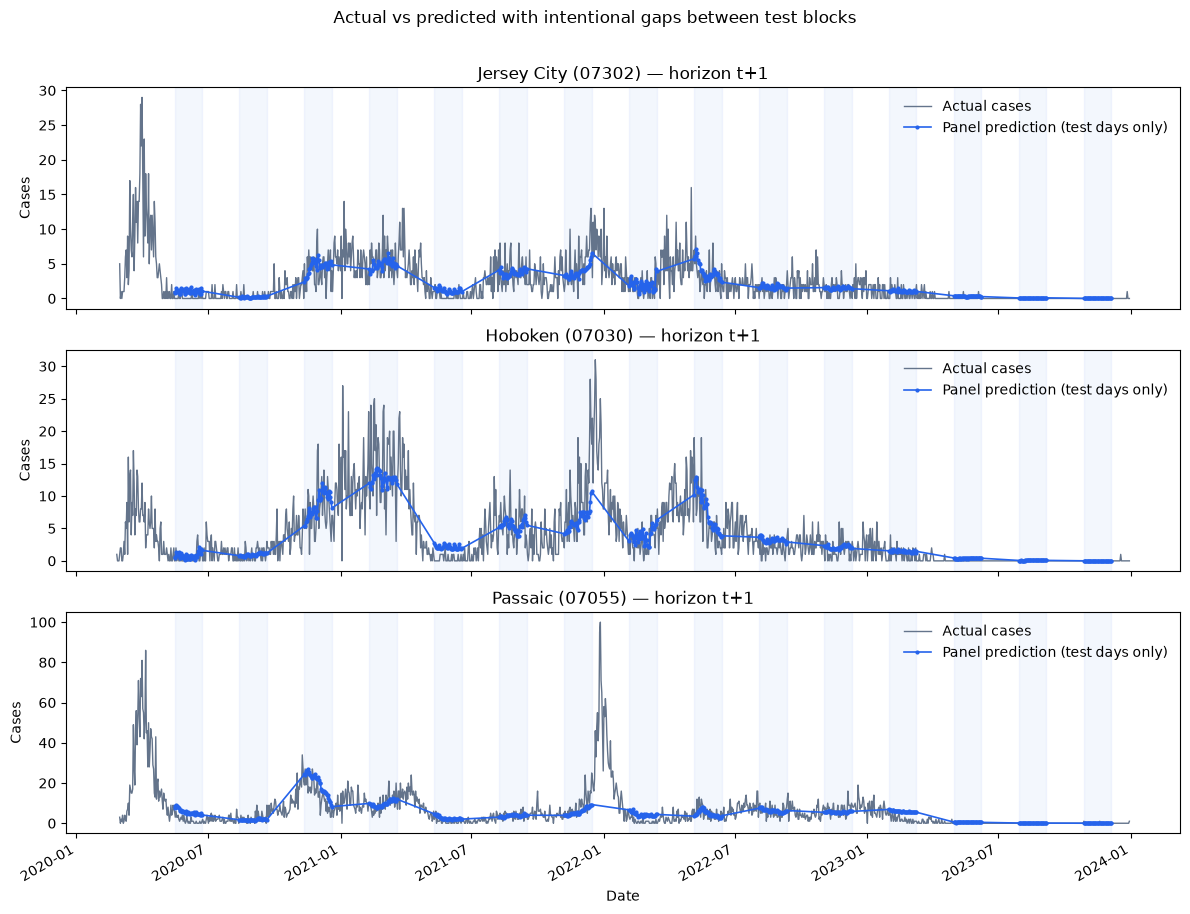

Figures saved to /Users/dhruvesh/Desktop/Fall 2026/Analytics/Jupyter/Weikun/rolling_dynamic_panel/window_90days/outputs/figures


In [10]:
# Plot B — actual path vs test-only predictions for three ZIPs (horizon 1)
# Predictions are drawn on target_date so they line up with the outcome day.
places = {
    "07302": "Jersey City",
    "07030": "Hoboken",
    "07055": "Passaic",
}

actual_panel = horizons[1].loc[horizons[1].zip.isin(places), ["zip", "date", "cases_today"]].copy()
pred_h1 = predictions.loc[
    predictions.horizon_days.eq(1) & predictions.zip.isin(places),
    ["zip", "date", "target_date", "actual_cases", "panel_prediction", "window_id"],
].copy()

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (zipcode, name) in zip(axes, places.items()):
    actual = actual_panel.loc[actual_panel.zip.eq(zipcode)].sort_values("date")
    pred = pred_h1.loc[pred_h1.zip.eq(zipcode)].sort_values("target_date")

    ax.plot(actual.date, actual.cases_today, color="#64748B", linewidth=1, label="Actual cases")
    ax.plot(
        pred.target_date, pred.panel_prediction,
        color="#2563EB", linewidth=1.2, marker="o", markersize=2,
        label="Panel prediction (test days only)",
    )

    for _, w in metrics.loc[metrics.horizon_days.eq(1), ["test_start", "test_end"]].drop_duplicates().iterrows():
        # Shade outcome days covered by this test block for horizon 1 (test_start+1 .. test_end+1).
        ax.axvspan(w.test_start + pd.Timedelta(days=1), w.test_end + pd.Timedelta(days=1), color="#2563EB", alpha=0.05)

    ax.set_ylabel("Cases")
    ax.set_title(f"{name} ({zipcode}) — horizon t+1")
    ax.legend(frameon=False, loc="upper right")

axes[-1].set_xlabel("Date")
fig.suptitle("Actual vs predicted with intentional gaps between test blocks", y=1.01)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
fig.savefig(FIGDIR / "actual_vs_predicted_selected_zips_h1.png", dpi=150)
plt.show()

print("Figures saved to", FIGDIR.resolve())


## Done (90-day track)

Same pipeline as the 60-day folder, with 90-day training and 39-day testing. Outputs live in this folder’s `outputs/`.

Compare against `../window_60days/outputs/` when you discuss how training-window length changes skill and MAE.